# Practical 2 report: from relationships to predictive models

**Student:** Nataliia Vytska
**Date:** 30/09/2026
**Practical:** 2 - Regression and evaluation

In [1]:
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy import stats
import dcor
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 170926

diabetes = load_diabetes(as_frame=True)
diabetes_df = diabetes.frame.copy()

TARGET_D = "target"
predictors_d = [c for c in diabetes_df.columns if c != TARGET_D]


def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)}

## 2. Data-preparation readiness

Complete the checklist before describing modelling results. Tick an item only after checking the data or documenting a justified decision.

### Scientific purpose and provenance

- [x] Is the biological question and prediction task stated clearly?
  — Yes: Regression task.
- [x] Is the unit of observation clear?
  — Yes: one row is one patient.
- [x] Do I know where the data came from, how they were generated, and under which access conditions they may be used?
  — Yes: scikit-learn built-in dataset load_diabetes, free to use for learning.
- [x] Have I recorded the data version, processing history, and transformations already applied?
  — Yes: predictors are already mean-centered and scaled by sklearn, the target is not scaled.

In [2]:
print("Shape:", diabetes_df.shape)
print("sklearn version:", sklearn.__version__)

Shape: (442, 11)
sklearn version: 1.9.0


### Table shape and identifiers

- [x] Is the table tidy: one observation per row, one variable per column, and one value per cell?
  — Yes: one patient per row.
- [x] If needed, have I transposed the original assay into the format expected by the analysis tool?
  — Not needed: rows are already patients.
- [x] Are row names, column names, and identifiers clear, unique, and stable?
  — Yes: column names are unique.
- [ ] Can every feature and observation be traced to its source?
  — Partly: features are named, but without patient IDs rows cannot be traced back to real patients.
- [x] Are the feature matrix and metadata aligned by an explicit identifier rather than row order?
  — Not needed: features and target are in the same table.

In [28]:
print("Column names unique:", diabetes_df.columns.is_unique)
diabetes_df.head()

Column names unique: True


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### Types, values, and measurement meaning

- [x] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
  — Yes: all columns are numeric, but sex is actually categorical.
- [ ] Are units, scales, encodings, reference categories, and detection limits understood?
  — Partly: predictors are scaled, so original units are lost. It is not documented which sex value is male or female.
- [x] Have impossible values, inconsistent labels, unexpected categories, constant features, and extreme values been checked?
  — Yes: no constant features, no infinite values, sex has exactly 2 values, target is within 25–346.
- [x] Are normalization, scaling, log transformation, and batch-correction steps documented?
  — Well, yes: scaling was done by sklearn even before I got the data.

In [4]:
print("Constant features:", (diabetes_df.nunique() <= 1).sum())
print("Non-finite values:", (~np.isfinite(diabetes_df)).sum().sum())
print("sex values:", diabetes_df["sex"].nunique())
diabetes_df.describe().round(3)

Constant features: 0
Non-finite values: 0
sex values: 2


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


### Missing values

- [x] Have missing values been detected using all representations, not only `NaN`?
  — Yes: all columns are numeric and there are no NaN or placeholder values.
- [x] Have missing values been measured by row, column, and relevant group?
  — Yes: 0 missing values everywhere.
- [x] Do I know whether missingness is structural, technical, or plausibly related to biology or the target?
  — Not needed: there is no missing data.
- [x] Have retention, removal, or imputation been justified?
  — Nothing to remove or impute.
- [x] If imputing, will the imputer be fitted on training data only?
  — Not needed.

In [29]:
print("Missing values:", diabetes_df.isna().sum().sum())

Missing values: 0


### Replicates, dependence, and grouping

- [x] Have exact and near-duplicate observations been checked?
  — Yes: 0 duplicate rows.
- [x] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
  — Independent samples: one row per patient.
- [x] Is the independent biological unit identified by a grouping variable?
  — The unit is the patient, and each patient is one row, so no grouping variable were needed.
- [x] Will related observations remain in the same train/validation/test split?
  — There are no related observations, so a simple random split is ok here.
- [x] Is the provenance of synthetic or augmented observations recorded?
  — Not needed: no synthetic data.

In [30]:
print("Duplicate rows:", diabetes_df.duplicated().sum())

Duplicate rows: 0


### Target, leakage, confounding, and reproducibility

- [x] Is the target defined before modelling?
  — Yes: target = disease progression one year after baseline.
- [x] Have identifiers, post-outcome variables, duplicated target information, and other leakage sources been excluded?
  — Yes: there are no ID columns, and all predictors are baseline measurements (taken before the outcome).
- [x] Have batch, site, subject, treatment, sex, age, time, and other possible confounders been considered?
  — Yes: age and sex are in the data; there is no information about site, time or treatment.
- [x] Does the planned split represent the biological generalization question?
  — Yes: a random split estimates performance on new patients from the same population.
- [x] Are random seeds, software versions, file names, shapes, and preprocessing decisions recorded?
  — Yes: RANDOM_STATE, data from load_diabetes(), shape 442 * 11, train 353 / test 89.

**Preparation summary:**

- Biological unit: one patient
- Number of observations and features: 442 patients, 10 predictors
- Target and feature definition: target = disease progression after one year, features = age, sex, bmi, bp, s1–s6
- Missing-value decision: no missing values
- Replicate/grouping decision: one row per patient, no grouping needed
- Train/test split and justification: random 80/20 split, because patients are independent
- Remaining concerns: small test set; predictors are scaled

## 3 Your task: Diabetes regression

### 3.1 Data presentation

- **One observation:** one patient (442 patients).
- **Target:** target — quantitative measure of disease progression one year after baseline.
- **Predictors (10):** age, sex, bmi , bp , s1–s6 (blood serum measurements).
- **Dimensionality:** 442 * 10 predictors, not a lot of features.

In [8]:
TARGET_D = "target"
predictors_d = [c for c in diabetes_df.columns if c != TARGET_D]

print("Shape:", diabetes_df.shape)
print("Predictors:", predictors_d)
print("Missing values:", diabetes_df.isna().sum().sum())
print("Duplicate rows:", diabetes_df.duplicated().sum())
diabetes_df[predictors_d].describe().round(4)

Shape: (442, 11)
Predictors: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Missing values: 0
Duplicate rows: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000
mean,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000
std,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476
min,-0.1072,-0.0446,-0.0903,-0.1124,-0.1268,-0.1156,-0.1023,-0.0764,-0.1261,-0.1378
25%,-0.0373,-0.0446,-0.0342,-0.0367,-0.0342,-0.0304,-0.0351,-0.0395,-0.0332,-0.0332
50%,0.0054,-0.0446,-0.0073,-0.0057,-0.0043,-0.0038,-0.0066,-0.0026,-0.0019,-0.0011
75%,0.0381,0.0507,0.0312,0.0356,0.0284,0.0298,0.0293,0.0343,0.0324,0.0279
max,0.1107,0.0507,0.1706,0.1320,0.1539,0.1988,0.1812,0.1852,0.1336,0.1356


### 3.2 Descriptive analysis

**Plot 1 — How is disease progression distributed among patients?**

count    442.0
mean     152.1
std       77.1
min       25.0
25%       87.0
50%      140.5
75%      211.5
max      346.0
Name: target, dtype: float64


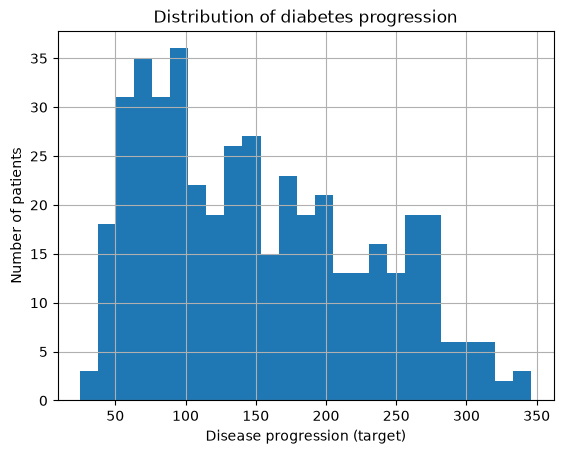

In [9]:
print(diabetes_df[TARGET_D].describe().round(1))

diabetes_df[TARGET_D].hist(bins=25)
plt.xlabel("Disease progression (target)")
plt.ylabel("Number of patients")
plt.title("Distribution of diabetes progression")
plt.show()

**Plot 2 — Are bmi, blood pressure, sex and HDL (s3) related to disease progression?**

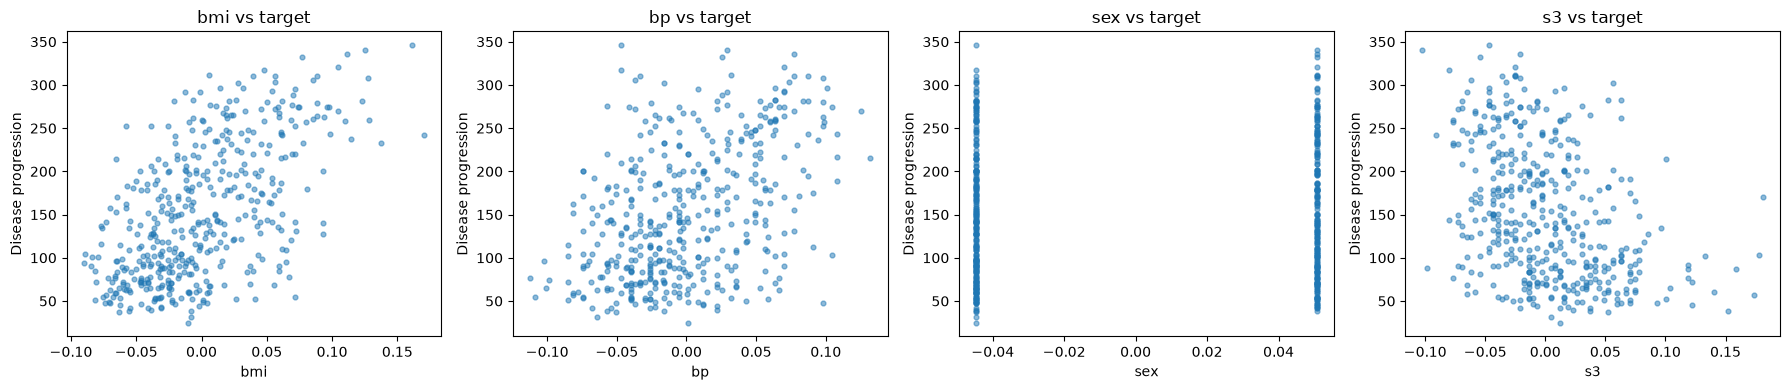

In [10]:
plot_features = ["bmi", "bp", "sex", "s3"]

fig, axes = plt.subplots(1, len(plot_features), figsize=(18, 4))
for ax, feature in zip(axes, plot_features):
    ax.scatter(diabetes_df[feature], diabetes_df[TARGET_D], alpha=0.5, s=12)
    ax.set_xlabel(f"{feature}")
    ax.set_ylabel("Disease progression")
    ax.set_title(f"{feature} vs target")
plt.tight_layout()
plt.show()

**Plot 3 — Does disease progression differ between the two sex groups?**

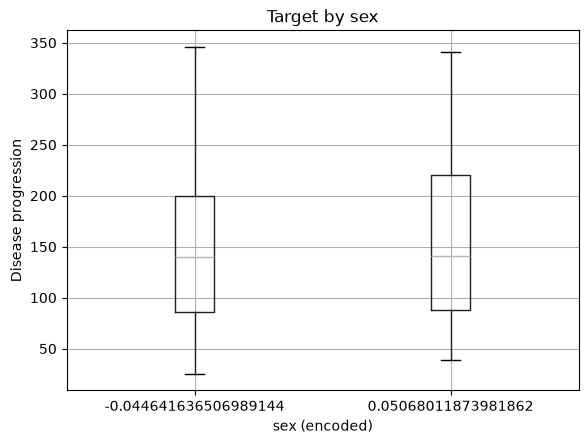

In [11]:
diabetes_df.boxplot(column=TARGET_D, by="sex")
plt.xlabel("sex (encoded)")
plt.ylabel("Disease progression")
plt.title("Target by sex")
plt.suptitle("")
plt.show()

**Conclusions**
- bmi shows the clearest positive relationship; the spread gets wider at higher bmi.
- bp is positively related but weaker.
- sex is categorical, so a scatter plot is not suitable; the boxplot shows almost no difference between the two groups.
- s3 is negatively related to the target.
- For all predictors the spread is large, so no single variable predicts progression precisely.

### 3.3 Correlation

In [12]:
corr_target = pd.DataFrame({
    "Pearson": diabetes_df[predictors_d].corrwith(diabetes_df[TARGET_D], method="pearson"),
    "Spearman": diabetes_df[predictors_d].corrwith(diabetes_df[TARGET_D], method="spearman")})
corr_target["diff"] = corr_target["Spearman"] - corr_target["Pearson"]
corr_target.sort_values("Pearson", key=abs, ascending=False).round(2)

,Pearson,Spearman,diff
bmi,0.59,0.56,-0.03
s5,0.57,0.59,0.02
bp,0.44,0.42,-0.03
s4,0.43,0.45,0.02
s3,-0.39,-0.41,-0.02
s6,0.38,0.35,-0.03
s1,0.21,0.23,0.02
age,0.19,0.20,0.01
s2,0.17,0.20,0.02
sex,0.04,0.04,-0.01


In [13]:
corr_target["dCor"] = [dcor.distance_correlation(diabetes_df[f].to_numpy(), diabetes_df[TARGET_D].to_numpy()) 
                       for f in corr_target.index]
corr_target.sort_values("dCor", ascending=False).round(2)

,Pearson,Spearman,diff,dCor
s5,0.57,0.59,0.02,0.56
bmi,0.59,0.56,-0.03,0.55
bp,0.44,0.42,-0.03,0.42
s4,0.43,0.45,0.02,0.42
s3,-0.39,-0.41,-0.02,0.39
s6,0.38,0.35,-0.03,0.35
s1,0.21,0.23,0.02,0.23
s2,0.17,0.20,0.02,0.19
age,0.19,0.20,0.01,0.19
sex,0.04,0.04,-0.01,0.05


**Conclusions**
- Strongest Pearson correlation with the target: bmi (0.59).
- Spearman ranks s5 first (0.59) and bmi second (0.56) — the ranking changes slightly.
- Pearson, Spearman and distance correlation give almost the same values, so the relationships are close to linear.

### 4.4 Simple regression

In [14]:
X_simple_d = diabetes_df[["bmi"]]
y_d = diabetes_df[TARGET_D]

simple_model_d = LinearRegression()
simple_model_d.fit(X_simple_d, y_d)

print("Intercept:", round(simple_model_d.intercept_, 2))
print("Slope:", round(simple_model_d.coef_[0], 2))
print("Slope per 1 SD of bmi:", round(simple_model_d.coef_[0] * diabetes_df["bmi"].std(), 1))

Intercept: 152.13
Slope: 949.44
Slope per 1 SD of bmi: 45.2


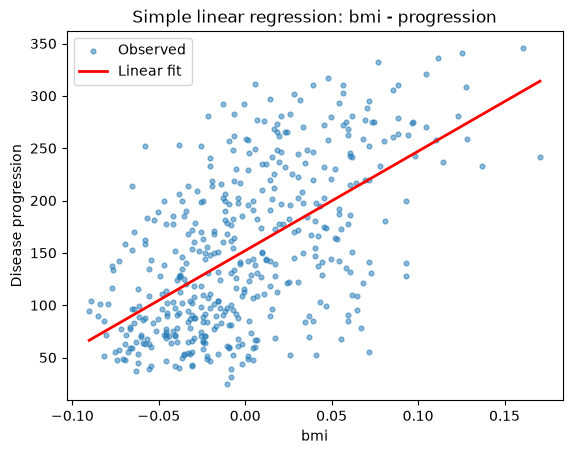

In [15]:
y_hat_simple_d = simple_model_d.predict(X_simple_d)
order_d = np.argsort(X_simple_d["bmi"].to_numpy())
plt.scatter(X_simple_d["bmi"], y_d, alpha=0.5, s=12, label="Observed")
plt.plot(X_simple_d["bmi"].to_numpy()[order_d], y_hat_simple_d[order_d],
         color="red", linewidth=2, label="Linear fit")
plt.xlabel("bmi")
plt.ylabel("Disease progression")
plt.title("Simple linear regression: bmi - progression")
plt.legend()
plt.show()

**Interpretation (bmi)**
- **Intercept = 152.1** 
- **Slope = 949** 


### 4.5 Residual diagnostics

In [16]:
residuals_d = y_d.to_numpy() - y_hat_simple_d

print("Mean residual:", round(residuals_d.mean(), 3))
print("Residual std:", round(residuals_d.std(), 1))
print("Min / max residual:", round(residuals_d.min()), "/", round(residuals_d.max()))

Mean residual: -0.0
Residual std: 62.4
Min / max residual: -165 / 155


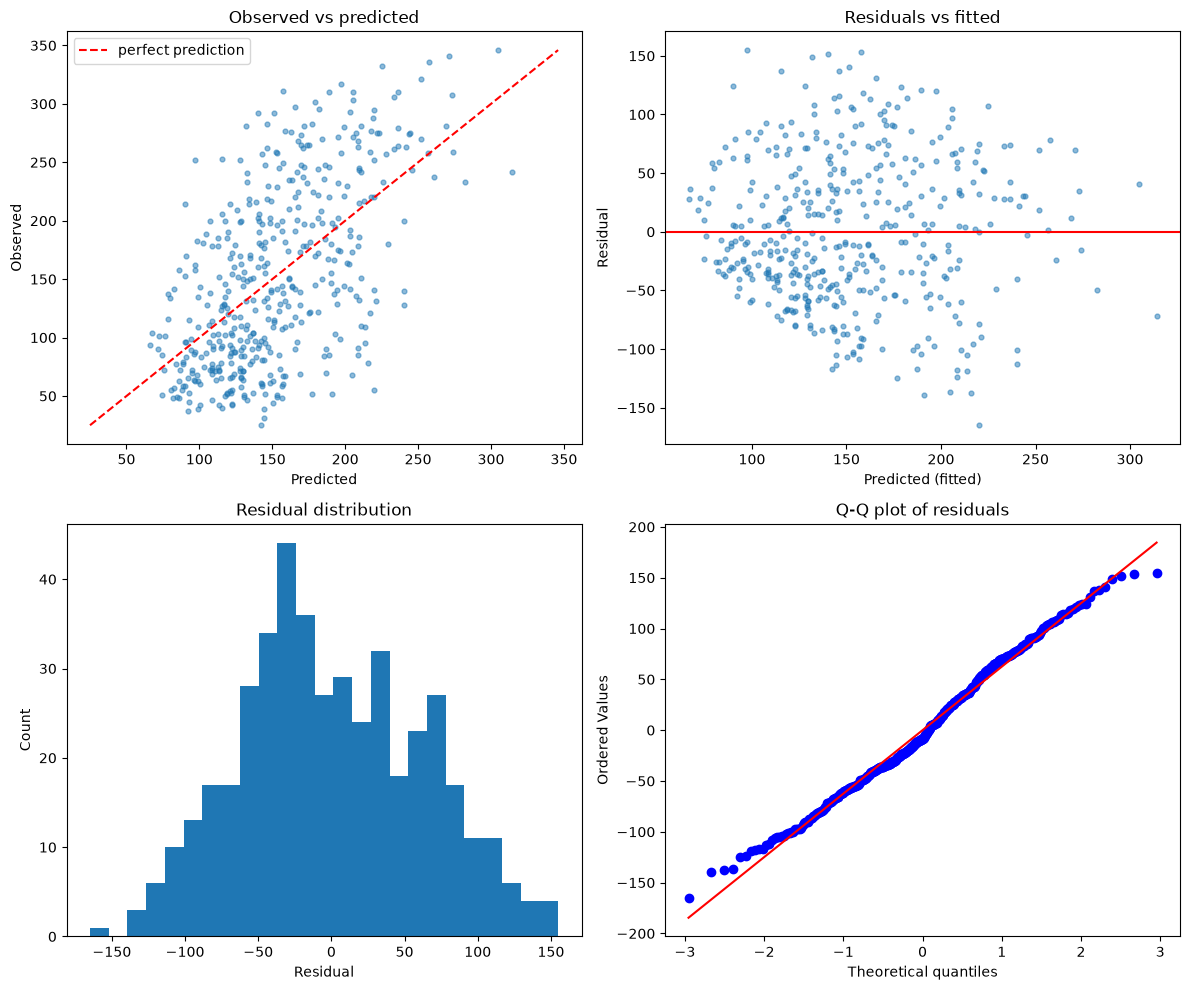

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

ax = axes[0, 0]
ax.scatter(y_hat_simple_d, y_d, alpha=0.5, s=12)
lims = [y_d.min(), y_d.max()]
ax.plot(lims, lims, color="red", linestyle="--", label="perfect prediction")
ax.set_xlabel("Predicted"); ax.set_ylabel("Observed")
ax.set_title("Observed vs predicted"); ax.legend()

ax = axes[0, 1]
ax.scatter(y_hat_simple_d, residuals_d, alpha=0.5, s=12)
ax.axhline(0, color="red")
ax.set_xlabel("Predicted (fitted)"); ax.set_ylabel("Residual")
ax.set_title("Residuals vs fitted")

ax = axes[1, 0]
ax.hist(residuals_d, bins=25)
ax.set_xlabel("Residual"); ax.set_ylabel("Count")
ax.set_title("Residual distribution")
stats.probplot(residuals_d, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot of residuals")

plt.tight_layout()
plt.show()

In [18]:
# Residual spread in three ranges of predictions + normality test
bins_d = pd.qcut(y_hat_simple_d, 3, labels=["low", "medium", "high"])
print(pd.Series(residuals_d).groupby(bins_d, observed=True).std().round(1))
print("Skewness:", round(stats.skew(residuals_d), 2))
print("Shapiro-Wilk p-value:", round(stats.shapiro(residuals_d).pvalue, 4))
print("Residuals beyond ±2 SD:", (np.abs(residuals_d) > 2 * residuals_d.std()).sum())

low       49.7
medium    68.6
high      68.4
dtype: float64
Skewness: 0.16
Shapiro-Wilk p-value: 0.0054
Residuals beyond ±2 SD: 13


**Diagnostics (bmi model)**
- **Linearity:** residuals vs fitted shows no clear curve, so a straight line is acceptable for bmi.
- **Homoscedasticity:** questionable — residual spread is smaller for low predictions than for medium/high ones. A likely reason is that the target cannot go below 25.
- **Normality:** the histogram is roughly bell-shaped, but the Q-Q plot deviates at the tails; the Shapiro–Wilk test rejects normality.
- **Unusual observations:** no extreme outliers.
- **Observed vs predicted:** wide cloud; the model pulls extreme values toward the mean.

### 4.6 Multiple regression and multicollinearity

In [19]:
X_multi_d = diabetes_df[predictors_d]

multi_model_d = LinearRegression()
multi_model_d.fit(X_multi_d, y_d)

coef_d = pd.DataFrame({
    "coefficient": multi_model_d.coef_,
    "coef_per_1SD": multi_model_d.coef_ * X_multi_d.std().to_numpy(),
    "Pearson_with_target": corr_target.loc[predictors_d, "Pearson"].to_numpy(),
}, index=predictors_d).round(2)
print("Intercept:", round(multi_model_d.intercept_, 2))
print("R² (all data):", round(r2_score(y_d, multi_model_d.predict(X_multi_d)), 3))
coef_d.sort_values("coefficient", key=abs, ascending=False)

Intercept: 152.13
R² (all data): 0.518


,coefficient,coef_per_1SD,Pearson_with_target
s1,-792.18,-37.72,0.21
s5,751.27,35.77,0.57
bmi,519.85,24.75,0.59
s2,476.74,22.70,0.17
bp,324.38,15.45,0.44
sex,-239.82,-11.42,0.04
s4,177.06,8.43,0.43
s3,101.04,4.81,-0.39
s6,67.63,3.22,0.38
age,-10.01,-0.48,0.19


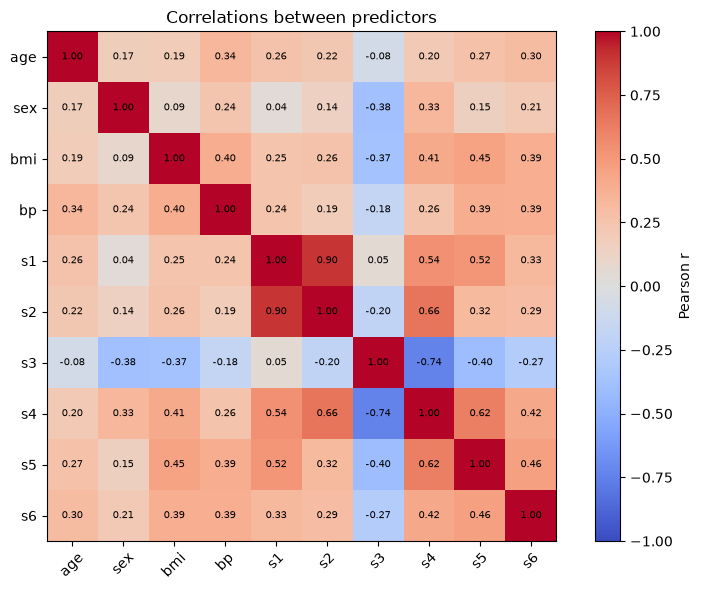

s1  s2    0.90
s3  s4   -0.74
s2  s4    0.66
s4  s5    0.62
s1  s4    0.54
    s5    0.52
dtype: float64

In [20]:
pred_corr = diabetes_df[predictors_d].corr()

plt.figure(figsize=(8, 6))
plt.imshow(pred_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson r")
plt.xticks(range(len(predictors_d)), predictors_d, rotation=45)
plt.yticks(range(len(predictors_d)), predictors_d)
for i in range(len(predictors_d)):
    for j in range(len(predictors_d)):
        plt.text(j, i, f"{pred_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Correlations between predictors")
plt.tight_layout()
plt.show()

upper_d = pred_corr.where(np.triu(np.ones(pred_corr.shape), k=1).astype(bool)).stack()
upper_d[upper_d.abs() > 0.5].sort_values(key=abs, ascending=False).round(2)

In [21]:
X_vif = sm.add_constant(X_multi_d)
vif_d = pd.Series(
    [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(predictors_d))],
    index=predictors_d, name="VIF").round(1)
vif_d.sort_values(ascending=False)

s1     59.2
s2     39.2
s3     15.4
s5     10.1
s4      8.9
bmi     1.5
bp      1.5
s6      1.5
sex     1.3
age     1.2
Name: VIF, dtype: float64

**Conclusions**
- **Multicollinearity:** s1 and s2 are strongly correlated  and have very high VIF; s3, s4, s5 are also correlated with each other.
- bmi, bp, age, sex, s6 have low VIF, so their coefficients are more reliable.

### 4.7 Train/test evaluation

In [22]:
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    diabetes_df[predictors_d], diabetes_df[TARGET_D],
    test_size=0.2, random_state=RANDOM_STATE)

print("Train:", X_train_d.shape, "| Test:", X_test_d.shape)
print("Target mean — train:", round(y_train_d.mean(), 1), "| test:", round(y_test_d.mean(), 1))

Train: (353, 10) | Test: (89, 10)
Target mean — train: 148.5 | test: 166.6


In [23]:
results_d = []
for model_name, features in [("Simple (bmi)", ["bmi"]), ("Multiple (all 10)", predictors_d)]:
    model = LinearRegression()
    model.fit(X_train_d[features], y_train_d)
    for split_name, X_split, y_split in [("train", X_train_d, y_train_d),("test", X_test_d, y_test_d)]:
        pred = model.predict(X_split[features])
        results_d.append({"model": model_name, "split": split_name,**regression_metrics(y_split, pred)})

results_d = pd.DataFrame(results_d).round(3)
results_d

,model,split,MAE,MSE,RMSE,R2
0,Simple (bmi),train,52.188,3911.727,62.544,0.331
1,Simple (bmi),test,50.152,3828.665,61.876,0.362
2,Multiple (all 10),train,43.488,2873.049,53.601,0.509
3,Multiple (all 10),test,42.381,2850.190,53.387,0.525


In [24]:
baseline_pred = np.full(len(y_test_d), y_train_d.mean())
print("Baseline test:", {k: round(v, 2) for k, v in regression_metrics(y_test_d, baseline_pred).items()})

Baseline test: {'MAE': 65.46, 'MSE': 6326.8, 'RMSE': np.float64(79.54), 'R2': -0.05}


**Conclusions**
- Random 80/20 split: 353 train / 89 test patients. A simple random split is fine because each row is an independent patient.
- Train and test scores are very close, so there is no overfitting.
- **Does the split answer the question?** It shows how well the model works for new patients from the same population. It says nothing about patients from other hospitals or other time periods. The test set is small, so results depend on the random split.

### 4.8 Independent-task conclusion

**1. Which model generalized better?**
The multiple model (all 10 predictors). On test data it has lower error and explains more variance.

**2. Did adding more variables help?**
Yes. Test R2 went up. Train and test scores are almost the same, so the model is not overfitting. But it still explains only about half of the variation.
a
**3. Are any regression assumptions questionable?**
Linearity looks ok. The residual spread is not equal (smaller errors for low predictions), and residuals are only roughly normal. But as I know it doesnt matter a lot for predictions.

**4. Are coefficient interpretations straightforward?**
No. The predictors are already scaled, so coefficients are not in real units. Also s1 and s2 are strongly correlated, so their coefficients are unstable and can even have the "wrong" sign.

**5. What is one important limitation?**
The dataset is small (89 patients in test), so results depend on the random split. Also, the original units are unknown, so it is hard to explain results in clinical terms.